# 0. Setup

Packages

In [1]:
# Copyright 2021 D-Wave Systems Inc.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

import argparse
import sys
# import matplotlib
import networkx as nx
from dimod import ConstrainedQuadraticModel, Binary, quicksum
from dwave.system import LeapHybridCQMSampler

try:
    import matplotlib.pyplot as plt
except ImportError:
    matplotlib.use("agg")
    import matplotlib.pyplot as plt

import pickle
from copy import deepcopy
import random
import numpy as np
from mycolorpy import colorlist as mcp

Functions

In [7]:
# # Function used for reading in command line arguments
# def read_in_args(args):
#     """ Read in user specified parameters."""

#     # Set up user-specified optional arguments
#     parser = argparse.ArgumentParser()
#     parser.add_argument("-g", "--graph", default='internet', choices=['karate', 'internet', 'rand-reg', 'ER', 'SF'], help='Graph to partition (default: %(default)s)')
#     parser.add_argument("-n", "--nodes", help="Set graph size for graph. (default: %(default)s)", default=1000, type=int)
#     parser.add_argument("-d", "--degree", help="Set node degree for random regular graph. (default: %(default)s)", default=4, type=int)
#     parser.add_argument("-p", "--prob", help="Set graph edge probability for ER graph. Must be between 0 and 1. (default: %(default)s)", default=0.25, type=float)
#     parser.add_argument("-e", "--new-edges", help="Set number of edges from new node to existing node in SF graph. (default: %(default)s)", default=4, type=int)

#     return parser.parse_args(args)

def build_graph(args):
    """ Builds graph from user specified parameters or use defaults."""

    max_vars = int(5000/3)
    
    # Build graph using networkx
    if args.graph == 'karate':
        print("\nReading in karate graph...")
        G = nx.karate_club_graph()
    elif args.graph == 'internet':
        if args.nodes < 1000 or args.nodes > max_vars:
            args.nodes = 1000
            print("\nSize for internet graph must be between 1000 and " + str(max_vars) + ". Setting size to 1000.\n")
        print("\nReading in internet graph of size", args.nodes, "...")
        G = nx.random_internet_as_graph(args.nodes)
    elif args.graph == 'rand-reg':
        if args.nodes < 1 or args.nodes > max_vars:
            print("\nSize for random regular graph must be between 1 and " + str(max_vars) + ". Setting size to 1000.\n")
        if args.degree < 0 or args.degree >= args.nodes:
            print("\nDegree must be between 0 and n-1. Setting size to min(4, n-1).\n")
            args.degree = min(4, args.nodes-1)
        if args.degree*args.nodes % 2 == 1:
            print("\nRequirement: n*d must be even.\n")
            if args.degree > 0:
                args.degree -= 1
                print("\nSetting degree to", args.degree, "\n")
            elif args.nodes-1 > args.degree:
                args.nodes -= 1
                print("\nSetting nodes to", args.nodes, "\n")
            else:
                print("\nSetting nodes to 1000 and degree to 4.\n")
                args.nodes = 1000
                args.degree = 4
        print("\nGenerating random regular graph...")
        G = nx.random_regular_graph(args.degree, args.nodes)
    elif args.graph == 'ER':
        if args.nodes < 1 or args.nodes > max_vars:
            print("\nSize for ER graph must be between 1 and " + str(max_vars) + ". Setting size to 1000.\n")
            args.nodes = 1000
        if args.prob < 0 or args.prob > 1:
            print("\nProbability must be between 0 and 1. Setting prob to 0.25.\n")
            args.prob = 0.25
        print("\nGenerating Erdos-Renyi graph...")
        G = nx.erdos_renyi_graph(args.nodes, args.prob)
    elif args.graph == 'SF':
        if args.nodes < 1 or args.nodes > max_vars:
            print("\nSize for SF graph must be between 1 and " + str(max_vars) + ". Setting size to 1000.\n")
            args.nodes = 1000
        if args.new_edges < 0 or args.new_edges > args.nodes:
            print("\nNumber of edges must be between 1 and n. Setting to 5.\n")
            args.new_edges = 5
        print("\nGenerating Barabasi-Albert scale-free graph...")
        G = nx.barabasi_albert_graph(args.nodes, args.new_edges)
    else:
        print("\nReading in karate graph...")
        G = nx.karate_club_graph()

    return G

# Visualize the input graph
def visualize_input_graph(G, save = False):
    """ Visualize graph to be partitioned."""

    pos = nx.spring_layout(G)
    nx.draw_networkx_nodes(G, pos, node_size=20, node_color='r', edgecolors='k')
    nx.draw_networkx_edges(G, pos, edgelist=G.edges(), style='solid', edge_color='#808080')
    # plt.draw()
    if save:
        plt.savefig('input_graph.png')
    plt.show()
    # plt.close()

def build_cqm_mod(G, size):
    """ Build the CQM for the problem instance."""

    # Two groups (cases 0, 1) and one separator group (case 2)
    num_groups = 3

    # Initialize the CQM object
    print("\nBuilding CQM...")
    cqm = ConstrainedQuadraticModel()

    # Build the CQM starting by creating variables
    vars = [[Binary(f'x_{name}_{i}') for i in range(num_groups)] for name in G.nodes()]

    # Set objective for CQM: minimize e(G1, G2)
    edge_sum = []
    for a, b in G.edges():
        if a != b:
            edge_sum.append(vars[a][0]*vars[b][1]+vars[a][1]*vars[b][0])
    cqm.set_objective(quicksum(edge_sum))

    # Add constraint to make variables discrete
    for v in range(len(vars)):
        cqm.add_discrete([f'x_{v}_{i}' for i in range(num_groups)])
        
    # Add constraint to CQM: |G3|=size
    g3 = [vars[i][2] for i in range(len(vars))]
    cqm.add_constraint(quicksum(g3) == size)

    # Add constraint to CQM: |G1|=|G2| (or within 1 if odd number to split)
    g1 = [vars[i][0] for i in range(len(vars))]
    g2 = [vars[i][1] for i in range(len(vars))]
    cqm.add_constraint(quicksum(g1) - quicksum(g2) <= 1)
    cqm.add_constraint(quicksum(g1) - quicksum(g2) >= -1)
    
    return cqm

def run_cqm_and_collect_solutions(cqm, sampler):
    """ Send the CQM to the sampler and return the best sample found."""

    # Initialize the solver
    print("\nSending to the solver...")
    
    # Solve the CQM problem using the solver
    sampleset = sampler.sample_cqm(cqm, label='Example - Immunization Strategy')

    # Get the first feasible solution
    feasible_sampleset = sampleset.filter(lambda d: d.is_feasible)
    if len(feasible_sampleset) == 0:
        print("\nNo feasible solution found. Returning best infeasible solution.")
        return sampleset.first.sample

    return feasible_sampleset.first.sample

def process_sample(G, sample):
    """ Interpret the CQM solution in terms of the partitioning problem."""

    # Display results to user
    group_1 = []
    group_2 = []
    sep_group = []
    results = [[],[],[]]
    for key, val in sample.items(): # key is of form "x_{node}_{group #}" and val is 0 or 1
        if val == 1:
            v = key.split("_")
            results[int(v[-1])].append(int(v[1]))

    group_1 = results[0]
    group_2 = results[1]
    sep_group = results[2]

    # Display best result
    print("\nPartition Found:")
    print("\tGroup 1: \tSize", len(group_1))
    print("\tGroup 2: \tSize", len(group_2))
    print("\tSeparator: \tSize", len(sep_group))

    print("\nSeparator Fraction: \t", len(sep_group)/len(G.nodes()))

    # Determines if there are any edges directly between the large groups
    illegal_edges = [(u, v) for u, v in G.edges if (sample[f'x_{u}_{0}']*sample[f'x_{v}_{1}'] == 1 or sample[f'x_{u}_{1}']*sample[f'x_{v}_{0}'] == 1)]

    print("\nNumber of illegal edges:\t", len(illegal_edges))

    return group_1, group_2, sep_group, illegal_edges

def visualize_results(G, group_1, group_2, sep_group, illegal_edges, save = False):
    """ Visualize the partition."""

    print("\nVisualizing output...")

    G1 = G.subgraph(group_1)
    G2 = G.subgraph(group_2)
    SG = G.subgraph(sep_group)

    pos_1 = nx.random_layout(G1, center=(-5,0))
    pos_2 = nx.random_layout(G2, center=(5,0))
    pos_sep = nx.random_layout(SG, center=(0,0))
    pos = {**pos_1, **pos_2, **pos_sep}

    nx.draw_networkx_nodes(G, pos_1, node_size=10, nodelist=group_1, node_color='#17bebb', edgecolors='k')
    nx.draw_networkx_nodes(G, pos_2, node_size=10, nodelist=group_2, node_color='#2a7de1', edgecolors='k')
    nx.draw_networkx_nodes(G, pos_sep, node_size=10, nodelist=sep_group, node_color='#f37820', edgecolors='k')

    nx.draw_networkx_edges(G, pos, edgelist=G.edges(), style='solid', edge_color='#808080')
    nx.draw_networkx_edges(G, pos, edgelist=illegal_edges, style='solid')

    # plt.draw()
    if save:
        output_name = 'separator.png'
        plt.savefig(output_name)
        print("\tOutput stored in", output_name)
    plt.show()
    # plt.close()
    

# --------------------------------------------
# Modified functions that use given separators
# --------------------------------------------

def build_cqm_from_sep(G, separators):
    """ Build the CQM for the problem instance."""

    # Two groups (cases 0, 1) and one separator group (case 2)
    # We will set case 2 using given separators, so really there are just two groups.
    num_groups = 3

    # Initialize the CQM object
    print("\nBuilding CQM...")
    cqm = ConstrainedQuadraticModel()

    # Build the CQM starting by creating variables
    # Separators fixed, so just two group variables per non-separator node
    vars = [[Binary(f'x_{name}_{i}') for i in range(num_groups - 1)] for name in G.nodes() if name not in separators]

    # Set objective for CQM: minimize e(G1, G2)
    edge_sum = []
    for a, b in G.edges():
        if a != b:
            if a not in separators and b not in separators:
                # indeces for vars is now different, so need to find index for node.
                a_index = vars.index([Binary(f'x_{a}_{i}') for i in range(num_groups - 1)])
                b_index = vars.index([Binary(f'x_{b}_{i}') for i in range(num_groups - 1)])
                edge_sum.append(vars[a_index][0]*vars[b_index][1]+vars[a_index][1]*vars[b_index][0])
    cqm.set_objective(quicksum(edge_sum))

    # Add constraint to make variables discrete
    # for v in range(len(vars)):
    #     cqm.add_discrete([f'x_{v}_{i}' for i in range(num_groups - 1)])
    for name in G.nodes():
        if name not in separators:
            cqm.add_discrete([f'x_{name}_{i}' for i in range(num_groups - 1)])
    
        
    # # Add constraint to CQM: |G3|=size
    # g3 = [vars[i][2] for i in range(len(vars))]
    # cqm.add_constraint(quicksum(g3) == len(separators))

    # Add constraint to CQM: |G1|=|G2| (or within 1 if odd number to split)
    g1 = [vars[i][0] for i in range(len(vars))]
    g2 = [vars[i][1] for i in range(len(vars))]
    cqm.add_constraint(quicksum(g1) - quicksum(g2) <= 1)
    cqm.add_constraint(quicksum(g1) - quicksum(g2) >= -1)
    
    return cqm

def process_sample_with_sep(G, sample, separators):
    """ Interpret the CQM solution in terms of the partitioning problem."""

    # Display results to user
    group_1 = []
    group_2 = []
    sep_group = []
    results = [[],[],[]]
    for key, val in sample.items(): # key is of form "x_{node}_{group #}" and val is 0 or 1
        if val == 1:
            v = key.split("_")
            results[int(v[-1])].append(int(v[1]))

    group_1 = results[0]
    group_2 = results[1]
    sep_group = separators

    # Display best result
    print("\nPartition Found:")
    print("\tGroup 1: \tSize", len(group_1))
    print("\tGroup 2: \tSize", len(group_2))
    print("\tSeparator: \tSize", len(sep_group))

    print("\nSeparator Fraction: \t", len(sep_group)/len(G.nodes()))

    # Determines if there are any edges directly between the large groups
    # To avoid key error, add condition that edge nodes are not in separators
    illegal_edges = [(u, v) for u, v in G.edges if (u not in separators and v not in separators) if (sample[f'x_{u}_{0}']*sample[f'x_{v}_{1}'] == 1 or sample[f'x_{u}_{1}']*sample[f'x_{v}_{0}'] == 1)]
                
    print("\nNumber of illegal edges:\t", len(illegal_edges))

    return group_1, group_2, illegal_edges


# Internet Network Case Study - Optimization

To showcase another use-case of the hubness optimization heuristic, we consider the network separation problem. We aim identify k=24-45 nodes to split the network of interest into two almost equal subgraphs with sizes, $N_{1}$ and $N_{2}$. The sizes are required to satisfy $N_{1} - N_{2} \leq 1$. The nodes are identified by identifying the set which will minimize the number of links connecting the two subgraphs. For computation reasons, We consider a subset of the Internet at the Autonomous System level, consisting of N = 1,000 nodes. 

Interpretation of the results of this optimization are in the notebook 'hubness_paper_pictures' in this folder. 

Input Graph

In [3]:
# # If you don't have input_graph.gml, use this cell to generate a new input graph. 

class Args(argparse.Namespace):
    graph = 'internet'
    nodes = 1000
    degree = 4
    prob = 0.25
    new_edges = 4

args=Args()

G = build_graph(args)

visualize_input_graph(G)

nx.write_gml(G, "input_graph.gml")

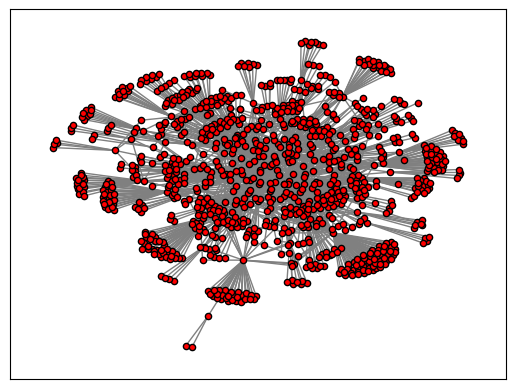

In [8]:
# Read previously generated input graph

G = nx.read_gml("input_graph.gml")

# Saving as gml saves integer node names as strings.
# Convert back to integers for use in functions.
G = nx.relabel_nodes(G, lambda x: int(x))

visualize_input_graph(G)

# 1. Getting Data

If you have saved data files, skip this section. Otherwise, uncomment cells to get new data.

In [5]:
# If you are getting new data, you will need to use your own API token from Leap
my_token = ""

## 1.1 Optimization Data

In [6]:
# # !!! Warning !!! This cell uses Hybrid solver time on Leap. 
# # You must use your own API token from Leap for my_token.

# # Initialize dictionary for saving results and list for saving hubness counts
results_dict = {}
hubness_list = [0 for i in range(1000)]

# # Iterate through size of separator class, from 25 to 50
for sep_size in range(25,51):
    
    print(f"Separator constraint = {sep_size}\n")
    
    # Build model with separation constraint
    cqm = build_cqm_mod(G, size = sep_size)

    # This is the part that uses up time on Leap.
    # Run optimization.
    sampler = LeapHybridCQMSampler(token=my_token)
    sample = run_cqm_and_collect_solutions(cqm, sampler)
    
    # Process results into classification groups and illegal edges
    group_1, group_2, sep_group, illegal_edges = process_sample(G, sample)

    visualize_results(G, group_1, group_2, sep_group, illegal_edges)
    print("-"*75+"\n\n\n\n")
    
    # Save results
    # unhappiness = (# illegal edges) + (# nodes could be moved to get almost-equal groups) + (# separator nodes off from target separator constraint)
    result = {
        'sep_group': sep_group,
        'illegal_edges': illegal_edges,
        'unhappiness': len(illegal_edges) + ( abs( len(group_1)-len(group_2) ) // 2 ) + abs(sep_size - len(sep_group)),
        'group_1': group_1,
        'group_2': group_2,
    }
    results_dict[sep_size] = deepcopy(result)
    # Update hubness
    for node in sep_group:
        hubness_list[node] += 1

In [7]:
# # Save results
# # !!! Warning !!! Be careful not to accidentally overwrite an existing pickle file

with open("results_dict_08-24-2023.pkl", "wb") as fp:   #Pickling
    pickle.dump(results_dict, fp)

with open("hubness_list_08-24-2023.pkl", "wb") as fp:   #Pickling
    pickle.dump(hubness_list, fp)

# # Sort nodes in descending order of hubness and save
sorted_hubness_nodes = [x for _,x in sorted(zip(hubness_list,list(range(1000))), reverse=True)]
with open("sorted_hubness_nodes_08-24-2023.pkl", "wb") as fp:   #Pickling
    pickle.dump(sorted_hubness_nodes, fp)

## 1.2 Using Hubness

In [8]:
# # !!! Warning !!! This cell uses time on Leap. 
# # You must use your own API token for my_token.

hubness_results_dict = {}

# # Iterate through size of separator class, from 25 to 50
for sep_size in range(25,51):
    
    separators = sorted_hubness_nodes[0:sep_size]
    
    print(f"Separator size = {sep_size}\n")
    
    # Build model with separation constraint
    cqm = build_cqm_from_sep(G, separators)

    # This is the part that uses up time on Leap.
    # Run optimization.
    sampler = LeapHybridCQMSampler(token=my_token)
    sample = run_cqm_and_collect_solutions(cqm, sampler)
    
    # Process results into classification groups and illegal edges
    group_1, group_2, illegal_edges = process_sample_with_sep(G, sample, separators)

    visualize_results(G, group_1, group_2, separators, illegal_edges)
    print("-"*75+"\n\n\n\n")
    
    # Save results
    # unhappiness = (# illegal edges) + (# nodes could be moved to get almost-equal groups) + (# separator nodes off from target separator constraint)
    result = {
        'sep_group': separators,
        'illegal_edges': illegal_edges,
        'unhappiness': len(illegal_edges) + ( abs( len(group_1)-len(group_2) ) // 2 ) + abs(sep_size - len(separators)),
        'group_1': group_1,
        'group_2': group_2,
    }
    hubness_results_dict[sep_size] = deepcopy(result)

In [9]:
# # Save results
# # !!! Warning !!! Be careful not to accidentally overwrite an existing pickle file

with open("hubness_results_dict_08-24-2023.pkl", "wb") as fp:   #Pickling
    pickle.dump(hubness_results_dict, fp)

## 1.3 Random Separators

In [10]:
# # !!! Warning !!! This cell uses time on Leap. 
# # You must use your own API token for my_token.

random_results_dict = {}

last_separators = results_dict[50]['sep_group']

# # Iterate through size of separator class, from 25 to 50
for sep_size in range(25,51):
    
    # From last optimization separators group, randomly sample sep_size number of separators
    separators = random.sample(last_separators, sep_size)
    
    print(f"Separator size = {sep_size}\n")
    
    # Build model with separation constraint
    cqm = build_cqm_from_sep(G, separators)

    # This is the part that uses up time on Leap.
    # Run optimization.
    sampler = LeapHybridCQMSampler(token=my_token)
    sample = run_cqm_and_collect_solutions(cqm, sampler)
    
    # Process results into classification groups and illegal edges
    group_1, group_2, illegal_edges = process_sample_with_sep(G, sample, separators)

    visualize_results(G, group_1, group_2, separators, illegal_edges)
    print("-"*75+"\n\n\n\n")
    
    # Save results
    # unhappiness = (# illegal edges) + (# nodes could be moved to get almost-equal groups) + (# separator nodes off from target separator constraint)
    result = {
        'sep_group': separators,
        'illegal_edges': illegal_edges,
        'unhappiness': len(illegal_edges) + ( abs( len(group_1)-len(group_2) ) // 2 ) + abs(sep_size - len(separators)),
        'group_1': group_1,
        'group_2': group_2,
    }
    random_results_dict[sep_size] = deepcopy(result)

In [11]:
# # Save results
# # !!! Warning !!! Be careful not to accidentally overwrite an existing pickle file

with open("random_results_dict_08-24-2023.pkl", "wb") as fp:   #Pickling
    pickle.dump(random_results_dict, fp)